# Import libraries

In [1]:
import sys
github_repo_url = "https://github.com/AnnaEls/HAADF-STEM-image-denoising.git"
!git clone {github_repo_url}
sys.path.append('/content/HAADF-STEM-image-denoising')

Cloning into 'HAADF-STEM-image-denoising'...
remote: Enumerating objects: 1679, done.
remote: Counting objects: 100% (180/180), done.
remote: Compressing objects: 100% (178/178), done.
remote: Total 1679 (delta 74), reused 2 (delta 2), pack-reused 1499 (from 1)
Receiving objects: 100% (1679/1679), 171.12 MiB | 12.29 MiB/s, done.
Resolving deltas: 100% (749/749), done.
Updating files: 100% (326/326), done.


In [2]:
import os
import tifffile
import numpy as np
import matplotlib.pyplot as plt

from Utilities.Utils import convert
from Analysis.gaussian_detection import detect_and_plot_gaussian_blobs, fit_2d_gaussians, gaussian_2d
from Analysis.intensity_analysis import cluster_gaussians_by_amplitude_and_plot, build_gaussian_training_data, build_gaussian_prediction_data, train_random_forest_classifier, to_numpy_labels, classification_metrics_to_dataframe
from Analysis.intensity_analysis import classify_intensities

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.metrics import classification_report, confusion_matrix
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from Analysis.gaussian_detection import detect_and_plot_gaussian_blobs, fit_2d_gaussians, gaussian_2d

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import profile_line


def get_linescan(image, start, end, linewidth=1, plot=True):
    """
    Extract an intensity line scan from an image.

    Parameters
    ----------
    image : 2D ndarray
        Input image.

    start : tuple
        (row, col) coordinates of the line start.

    end : tuple
        (row, col) coordinates of the line end.

    linewidth : int
        Width over which intensities are averaged.

    plot : bool
        Plot image, scan line, and intensity profile.

    Returns
    -------
    distance : ndarray
        Distance along the line in pixels.

    intensity : ndarray
        Intensity profile.
    """

    intensity = profile_line(
        image,
        start,
        end,
        linewidth=linewidth,
        reduce_func=np.mean,
        mode='reflect'
    )

    length = np.sqrt(
        (end[0] - start[0])**2 +
        (end[1] - start[1])**2
    )

    distance = np.linspace(0, length, len(intensity))

    if plot:
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(image, cmap='gray')

        ax.plot(
            [start[1], end[1]],
            [start[0], end[0]],
            'r-',
            linewidth=2
        )

        ax.scatter(
            [start[1], end[1]],
            [start[0], end[0]],
            c='red'
        )

        plt.show()

        plt.figure(figsize=(8, 4))
        plt.plot(distance, intensity)
        plt.xlabel('Distance (pixels)')
        plt.ylabel('Intensity')
        plt.xlim(0, length)
        plt.ylim(0, intensity.max())
        plt.tight_layout()
        plt.show()

    return distance, intensity

In [5]:

from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def classify_intensities(img, X, y, verbose=False):

    # ---- Gaussian detection and fitting ----
    gaussian_blobs = detect_and_plot_gaussian_blobs(
        img,
        min_sigma=1,
        max_sigma=30,
        num_sigma=10,
        threshold=0.2
    )

    fitted_gaussians = fit_2d_gaussians(
        img, gaussian_blobs, gaussian_2d
    )

    if fitted_gaussians is None or len(fitted_gaussians) == 0:
        return None

    # ---- Construct features for denoised image ----
    # Temporary labels, replaced by K-means below
    X_ns, _ = build_gaussian_training_data(
        fitted_gaussians,
        np.zeros(len(fitted_gaussians), dtype=int)
    )

    if len(X_ns) < 3:
        return None

    # ---- Independent K-means on denoised amplitudes ----
    amp_col = "amplitude"  # Adjust if your column has another name

    kmeans = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=20
    )

    cluster_ids = kmeans.fit_predict(
        X_ns[[amp_col]].to_numpy()
    )

    # ---- Align clusters by mean amplitude ----
    # Reference classes are ordered from lowest to highest
    # mean amplitude, without assuming labels 0, 1, 2
    # already follow that order.

    y_np = to_numpy_labels(y)

    ref_means = {
        label: X.loc[y_np == label, amp_col].mean()
        for label in np.unique(y_np)
    }

    ref_order = sorted(ref_means, key=ref_means.get)

    denoised_centers = kmeans.cluster_centers_[:, 0]
    denoised_order = np.argsort(denoised_centers)

    label_mapping = {
        int(denoised_order[i]): ref_order[i]
        for i in range(3)
    }

    y_ns_np = np.array([
        label_mapping[label] for label in cluster_ids
    ])

    # ---- Position matching ----
    pos_cols = ['x0', 'y0']
    max_dist = 6
    point_size = 80

    X_pos = X[pos_cols].to_numpy()
    X_ns_pos = X_ns[pos_cols].to_numpy()

    C = cdist(X_ns_pos, X_pos, metric="euclidean")
    row_ind, col_ind = linear_sum_assignment(C)

    matched_dist = C[row_ind, col_ind]
    valid = matched_dist < max_dist

    # ---- Compare ground truth and denoised classes ----
    y_true = y_np[col_ind[valid]]
    y_pred = y_ns_np[row_ind[valid]]

    if len(y_true) == 0:
        return None

    # ---- Metrics ----
    acc = accuracy_score(y_true, y_pred)

    result = classification_metrics_to_dataframe(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        total_gaussians=len(X_ns),
        matched=valid.sum()
    )

    # ---- Misclassifications ----
    mis_mask = y_true != y_pred
    mis_idx = np.where(mis_mask)[0]

    matched_pos = X_ns_pos[row_ind[valid]]
    mis_pos = matched_pos[mis_mask]

    if verbose:
        cm = confusion_matrix(
            y_true, y_pred, labels=[0, 1, 2]
        )

        print("===== METRICS =====")
        print(f"Total Gaussians: {len(X_ns)}")
        print(f"Matched: {valid.sum()}")
        print(f"Accuracy: {acc:.4f}\n")

        print("Reference class means:", ref_means)
        print("Denoised cluster centers:", denoised_centers)
        print("Cluster mapping:", label_mapping)

        print("\nConfusion Matrix:")
        print(cm)

        print("\nClassification Report:")
        print(classification_report(
            y_true, y_pred,
            labels=[0, 1, 2],
            zero_division=0
        ))

        print(f"Misclassified points: {len(mis_idx)}")

        # ---- Plot ----
        plt.figure(figsize=(8, 8))

        h, w = img.shape[:2]
        plt.imshow(
            img,
            cmap="gray",
            extent=[0, w, h, 0]
        )
        plt.axis("off")

        # Original colors: blue, brown, cyan
        class_cmap = ListedColormap([
            'tab:blue',
            'tab:brown',
            'tab:cyan'
        ])

        plt.scatter(
            matched_pos[~mis_mask, 0],
            matched_pos[~mis_mask, 1],
            c=y_pred[~mis_mask],
            cmap=class_cmap,
            vmin=-0.5,
            vmax=2.5,
            s=point_size,
            edgecolors="k",
            linewidths=0.5,
            label="Correct"
        )

        plt.scatter(
            mis_pos[:, 0],
            mis_pos[:, 1],
            marker="x",
            c="red",
            s=point_size * 1.2,
            linewidths=2,
            label="Misclassified"
        )

        plt.legend(
            loc="lower center",
            ncol=2,
            frameon=True
        )
        plt.tight_layout()
        plt.show()

    return result, y_true, y_pred, matched_pos, mis_pos


# Clean image intensities classification

In [6]:
dataset_path = '/content/HAADF-STEM-image-denoising/Datasets/DATASET_MXENE/'
path_to_clean_image = dataset_path + '080kVTi3C2O2-DEMO-80kV-ground_truth_interp_0.1_dose_no_noise.tif'
clean_image = convert(tifffile.imread(path_to_clean_image))

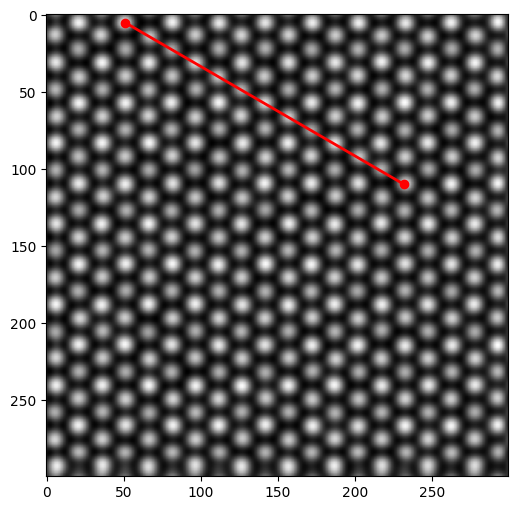

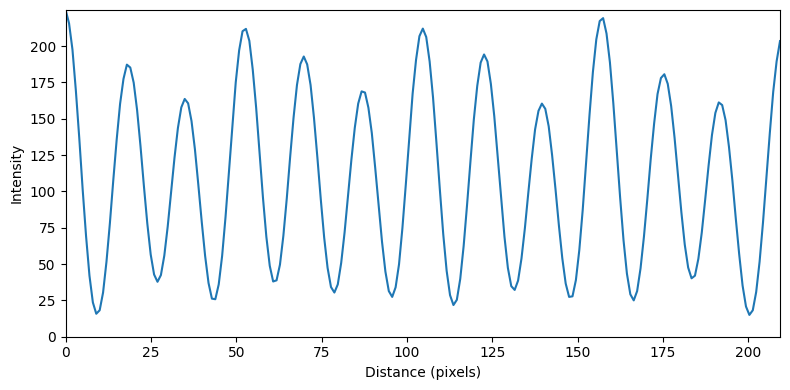

In [7]:
start = (5, 51)   # (row, column)
end   = (110, 232)

distance, intensity = get_linescan(
    clean_image,
    start,
    end,
    linewidth=5
)

Detected 340 Gaussian peaks.


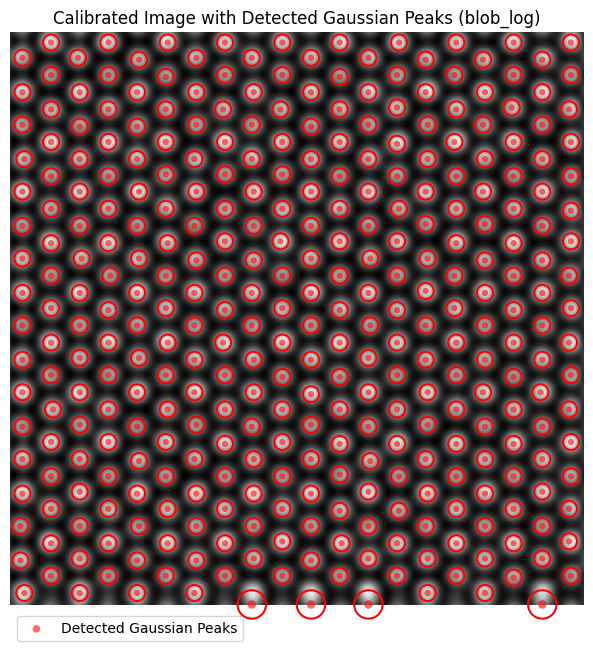

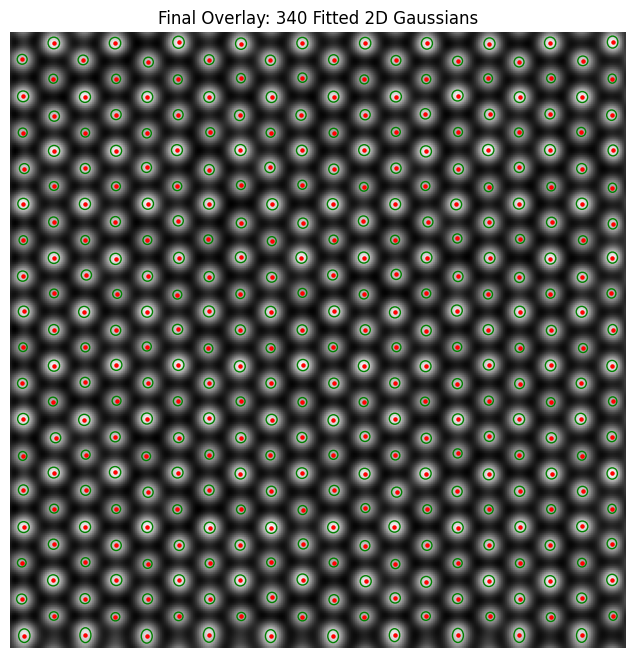

Successfully fitted and plotted 340 Gaussians.
K-Means clustering completed for 340 Gaussians.
First 10 cluster labels: [2 2 2 2 2 2 2 2 2 2]


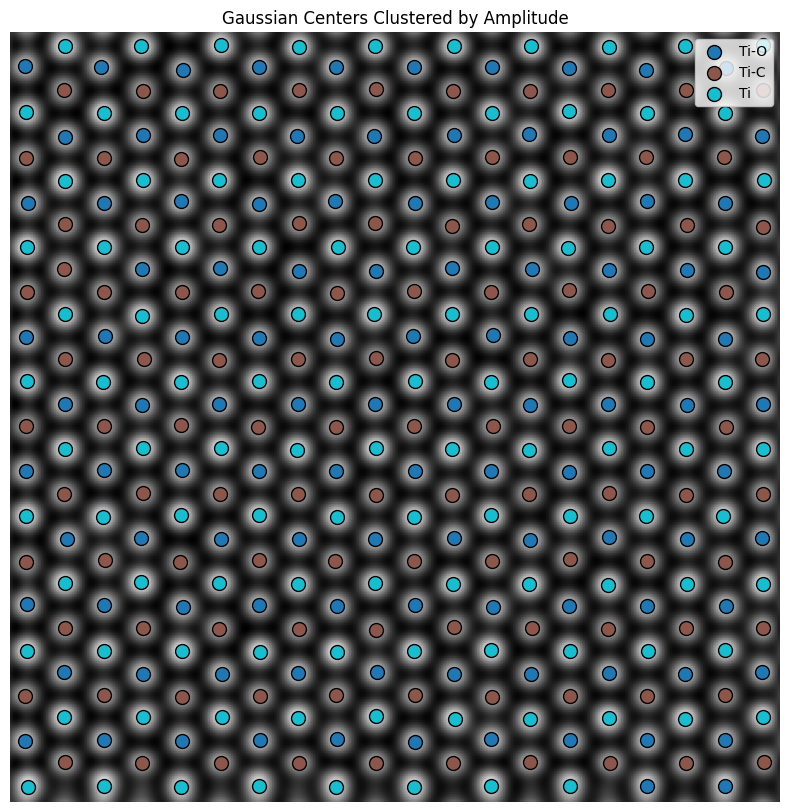

In [8]:
  image = clean_image
  gaussian_blobs = detect_and_plot_gaussian_blobs(image, min_sigma=1, max_sigma=30, num_sigma=10, threshold=0.2)
  gaussians = fit_2d_gaussians(image, gaussian_blobs, gaussian_2d)
  cluster_labels_clean = cluster_gaussians_by_amplitude_and_plot(image, gaussians)
  X_clean, y_clean = build_gaussian_training_data(gaussians, cluster_labels_clean[0])

In [9]:
X_clean

,amplitude,x0,y0,sigma_x,sigma_y,offset
0,212.714295,36.012892,31.113759,2.697331,2.666122,68.513893
1,214.028618,142.141109,161.704501,2.712612,2.741343,69.166631
2,214.721202,126.737988,240.931258,2.699620,2.714577,70.699609
3,216.418226,232.407390,56.975162,2.745746,2.719824,70.921835
4,208.091425,262.688519,109.819390,2.650433,2.688089,68.263462
...,...,...,...,...,...,...
335,109.883945,5.683214,205.969928,2.042266,2.140437,81.735623
336,184.348792,156.865477,293.741438,2.594985,3.131826,76.927631
337,185.322477,126.454222,293.697773,2.577678,3.130844,76.719596
338,192.462147,186.766569,293.244539,2.547982,3.142540,76.613075


# Doses

In [11]:
doses = [1000000.0, 500000.0, 100000.0, 50000.0,10000.0, 5000.0, 1000.0]

# LOBATO

In [ ]:
imgs_lobato = []
results_lobato  = []
for dose in doses:
  print(f'DOSE: {dose}')
  path_to_images = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_MXENE/denoised_lobato/'
  path_to_image = path_to_images + f'080kVTi3C2O2-DEMO-080kV-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif'
  image = convert(tifffile.imread(path_to_image))

  start = (5, 51)   # (row, column)
  end   = (110, 232)

  distance, intensity = get_linescan(
      image,
      start,
      end,
      linewidth=5)
  imgs_lobato.append(image)
  result, y_true, y_pred, matched_pos, mis_pos = classify_intensities(image, X_clean, y_clean, verbose=True)
  results_lobato.append([result, y_true, y_pred, matched_pos, mis_pos])

# PINTO

In [ ]:
imgs_pinto = []
results_pinto  = []
for dose in doses:
  print(f'DOSE: {dose}')
  path_to_images = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_MXENE/denoised_pinto/'
  path_to_image = path_to_images + f'080kVTi3C2O2-DEMO-080kV-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif'
  image = convert(tifffile.imread(path_to_image))
  imgs_pinto.append(image)
  result, y_true, y_pred, matched_pos, mis_pos = classify_intensities(image, X_clean, y_clean, verbose=True)
  results_pinto.append([result, y_true, y_pred, matched_pos, mis_pos])

# UNIT

In [ ]:
imgs_unit = []
results_unit  = []
for dose in doses:
  print(f'DOSE: {dose}')
  path_to_images = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_MXENE/denoised_unit_new/'
  path_to_image = path_to_images + f'080kVTi3C2O2-DEMO-080kV-jittered_interp_0.1_dose_{dose}_unit_aligned.tif'
  image = convert(tifffile.imread(path_to_image))
  start = (5, 51)   # (row, column)
  end   = (110, 232)

  distance, intensity = get_linescan(
      image,
      start,
      end,
      linewidth=5)
  imgs_unit.append(image)
  result, y_true, y_pred, matched_pos, mis_pos = classify_intensities(image, X_clean, y_clean, verbose=True)
  results_unit.append([result, y_true, y_pred, matched_pos, mis_pos])

# Hybrid

DOSE: 1000000.0


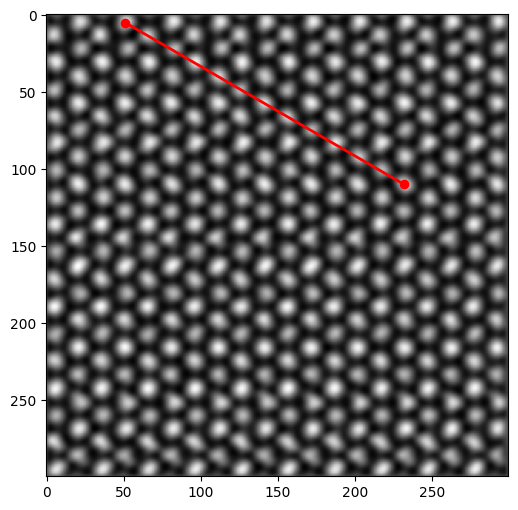

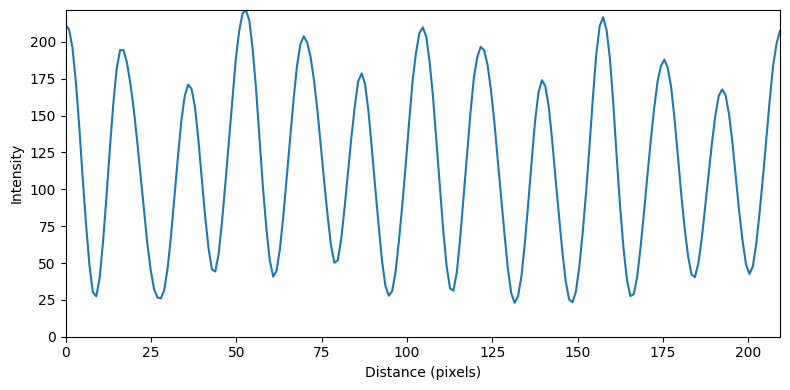

Detected 339 Gaussian peaks.


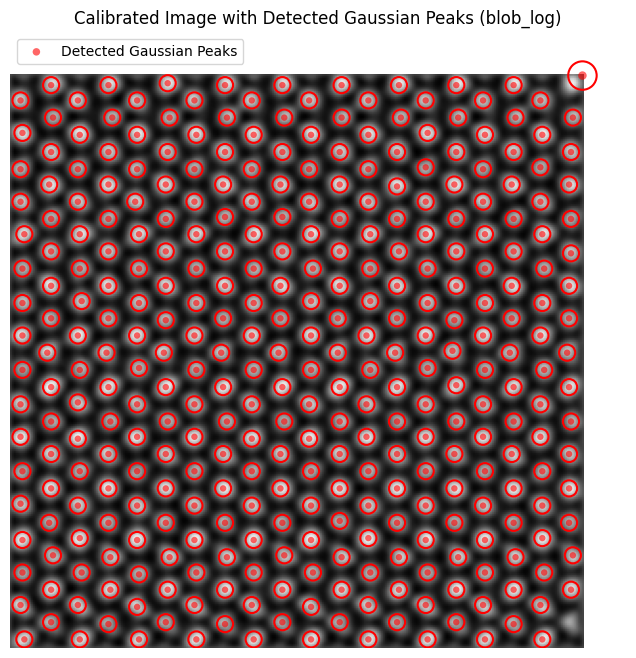

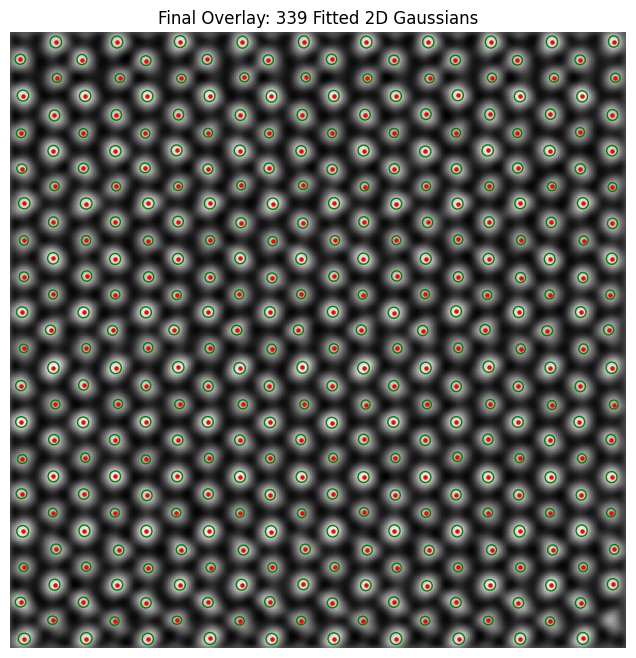

Successfully fitted and plotted 339 Gaussians.
===== METRICS =====
Total Gaussians: 339
Matched: 339
Accuracy: 0.9705

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [159.53685428 125.28902467 193.29916634]
Cluster mapping: {1: np.int32(1), 0: np.int32(0), 2: np.int32(2)}

Confusion Matrix:
[[105   2   4]
 [  1 109   0]
 [  3   0 115]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.95       111
           1       0.98      0.99      0.99       110
           2       0.97      0.97      0.97       118

    accuracy                           0.97       339
   macro avg       0.97      0.97      0.97       339
weighted avg       0.97      0.97      0.97       339

Misclassified points: 10


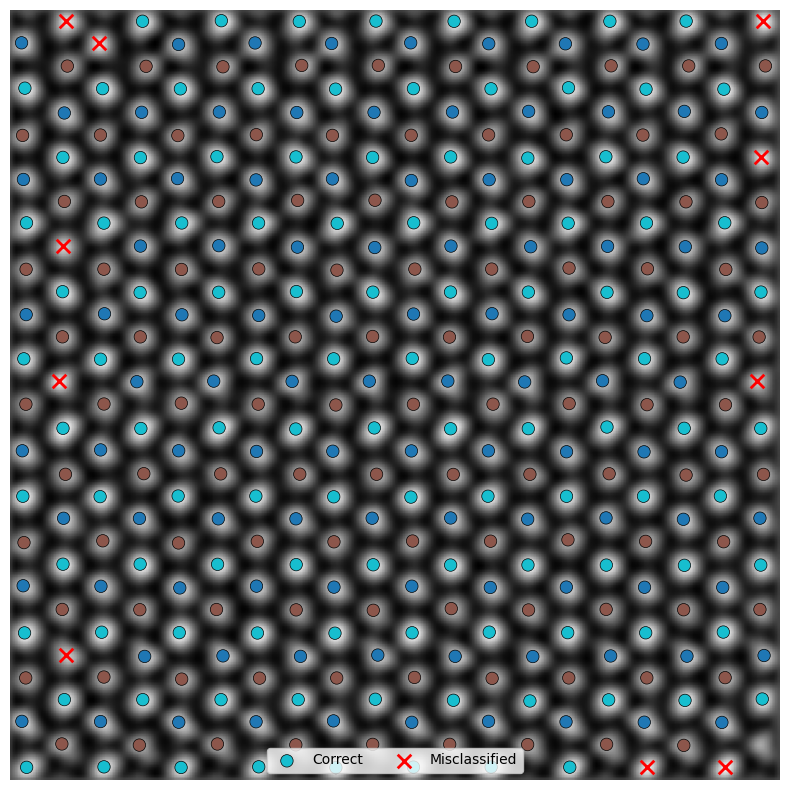

DOSE: 500000.0


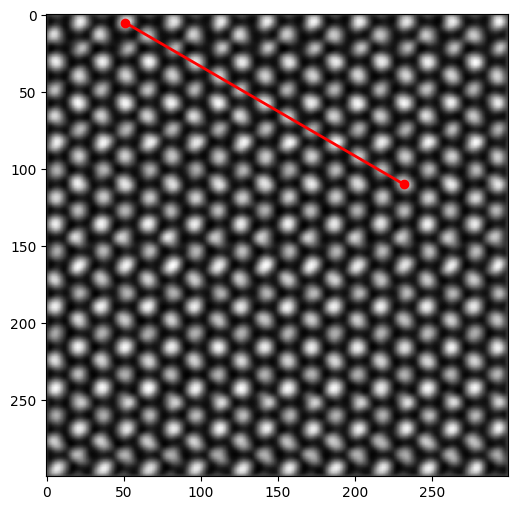

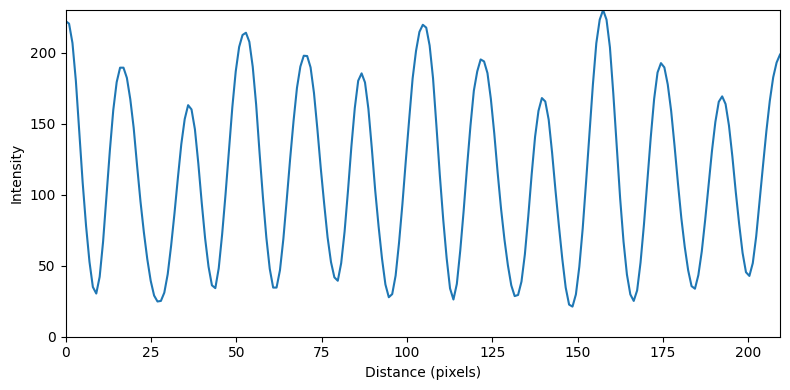

Detected 340 Gaussian peaks.


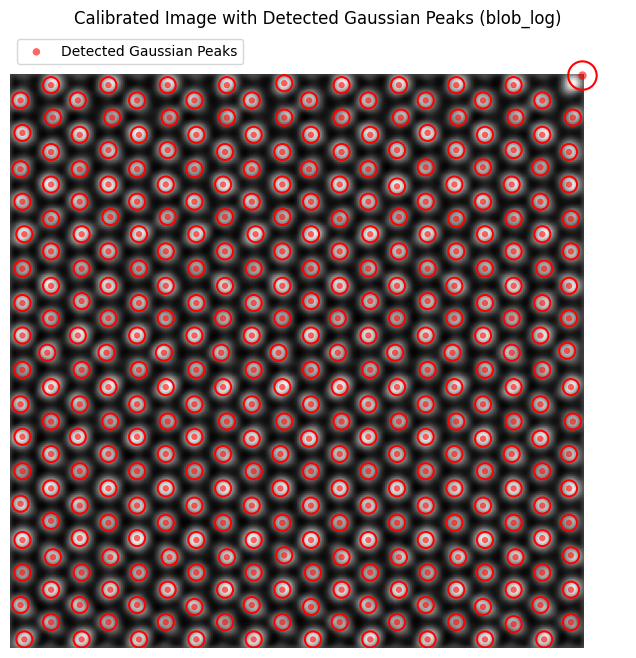

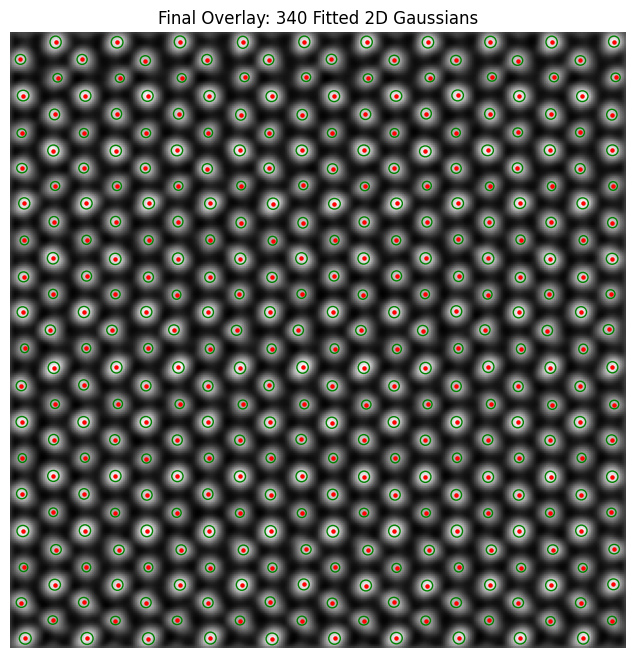

Successfully fitted and plotted 340 Gaussians.
===== METRICS =====
Total Gaussians: 340
Matched: 340
Accuracy: 0.9735

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [163.03922299 128.99437559 203.17928543]
Cluster mapping: {1: np.int32(1), 0: np.int32(0), 2: np.int32(2)}

Confusion Matrix:
[[106   2   3]
 [  3 108   0]
 [  1   0 117]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       111
           1       0.98      0.97      0.98       111
           2       0.97      0.99      0.98       118

    accuracy                           0.97       340
   macro avg       0.97      0.97      0.97       340
weighted avg       0.97      0.97      0.97       340

Misclassified points: 9


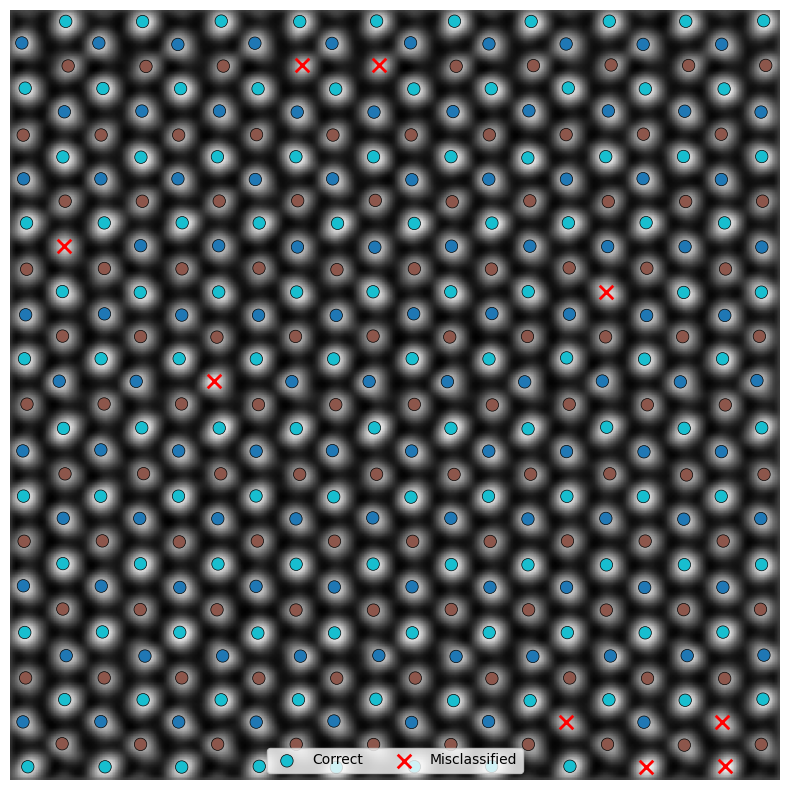

DOSE: 100000.0


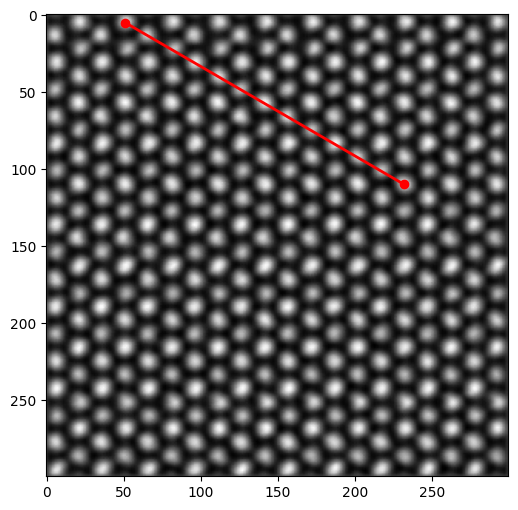

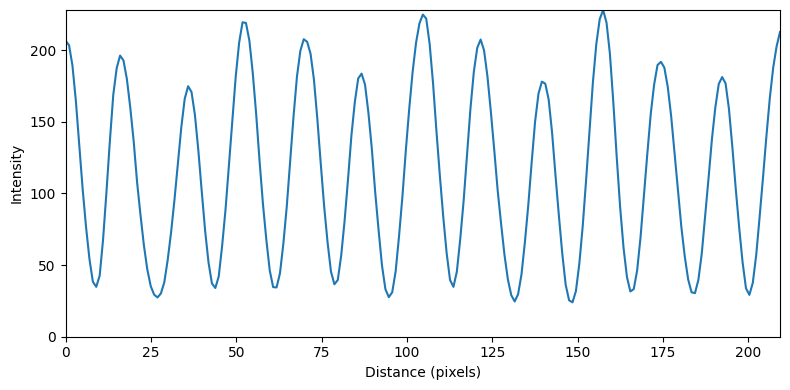

Detected 340 Gaussian peaks.


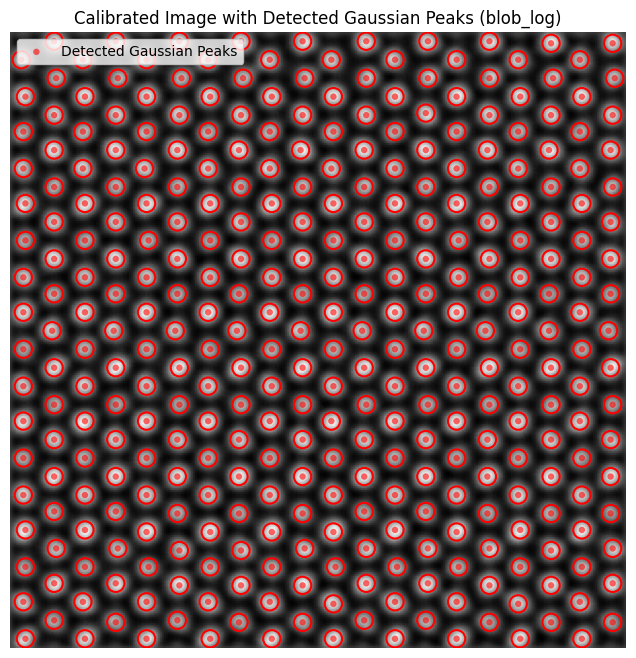

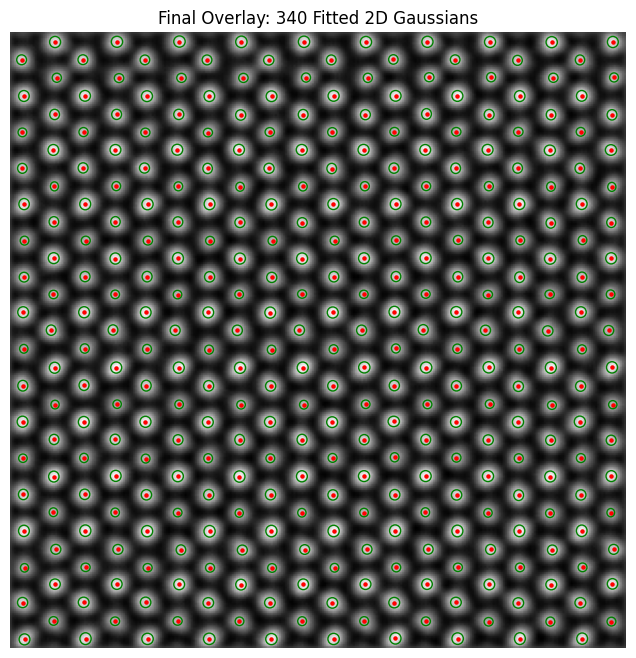

Successfully fitted and plotted 340 Gaussians.
===== METRICS =====
Total Gaussians: 340
Matched: 340
Accuracy: 0.9294

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [202.46850177 134.57245321 171.48263952]
Cluster mapping: {1: np.int32(1), 2: np.int32(0), 0: np.int32(2)}

Confusion Matrix:
[[101   6   4]
 [  5 106   0]
 [  9   0 109]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       111
           1       0.95      0.95      0.95       111
           2       0.96      0.92      0.94       118

    accuracy                           0.93       340
   macro avg       0.93      0.93      0.93       340
weighted avg       0.93      0.93      0.93       340

Misclassified points: 24


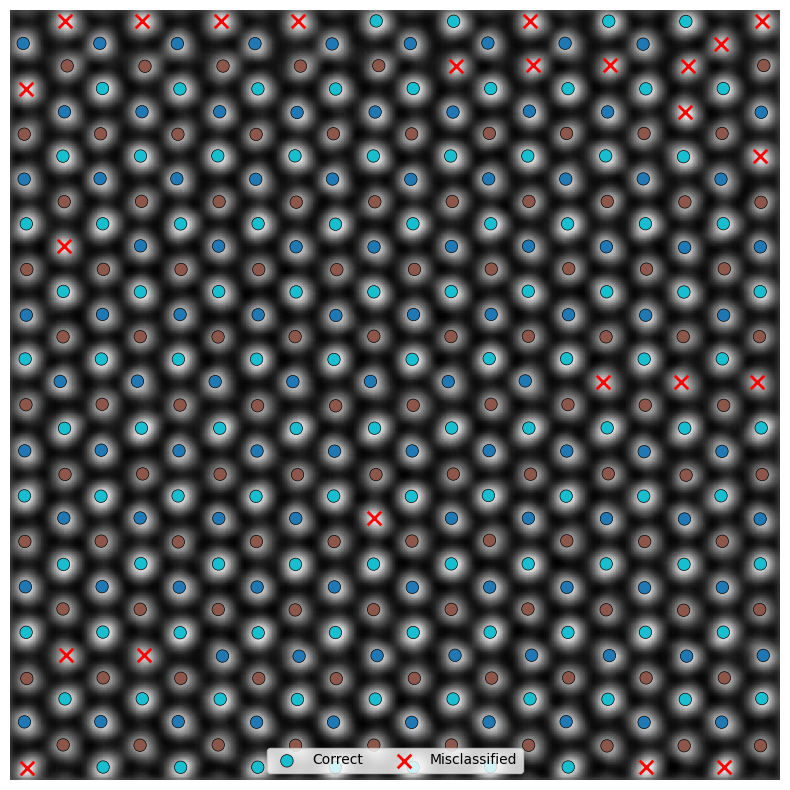

DOSE: 50000.0


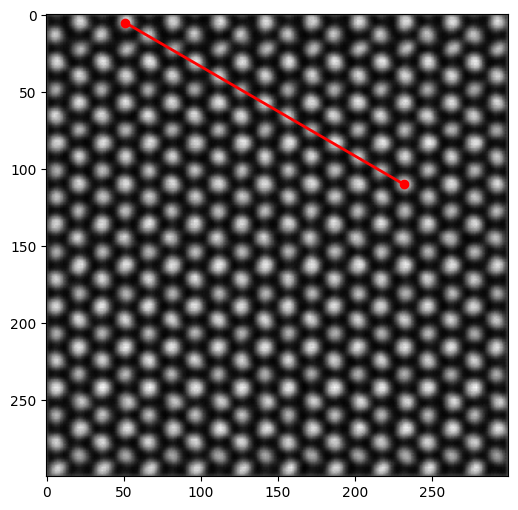

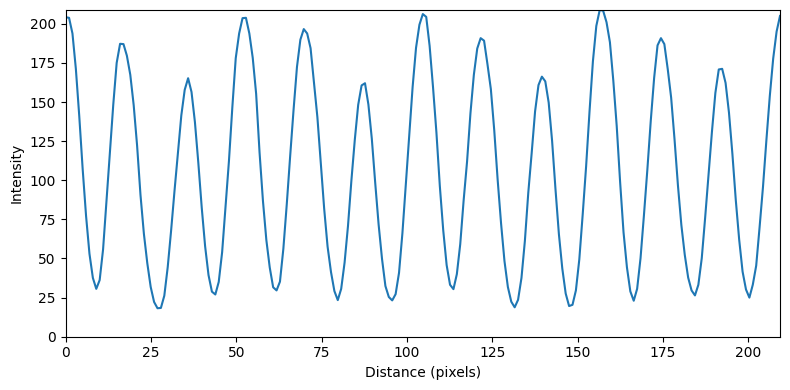

Detected 340 Gaussian peaks.


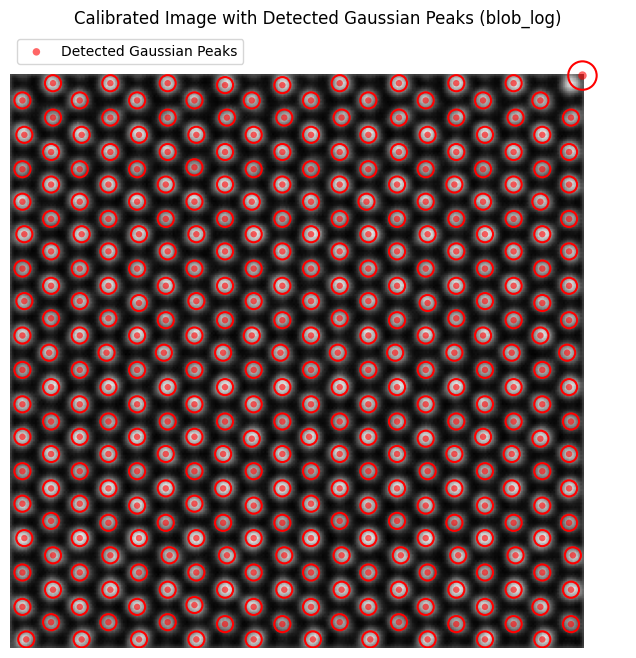

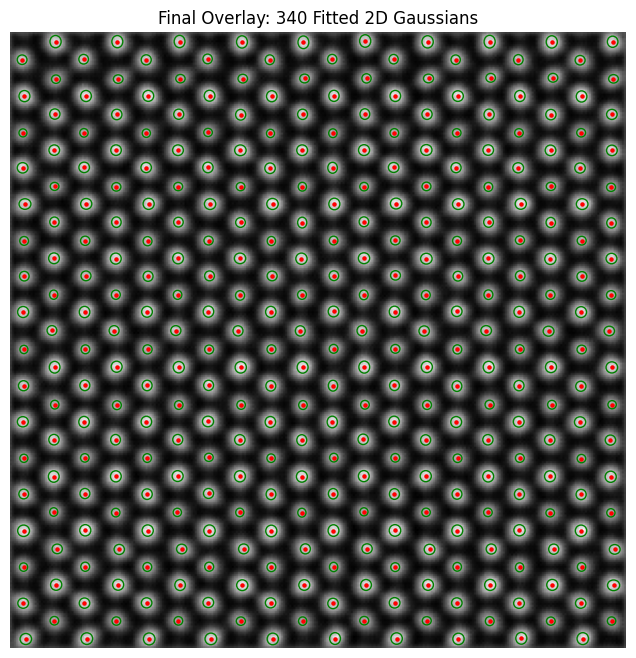

Successfully fitted and plotted 340 Gaussians.
===== METRICS =====
Total Gaussians: 340
Matched: 340
Accuracy: 0.9265

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [170.63304181 135.05340497 193.284155  ]
Cluster mapping: {1: np.int32(1), 0: np.int32(0), 2: np.int32(2)}

Confusion Matrix:
[[ 98   4   9]
 [  1 110   0]
 [ 11   0 107]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89       111
           1       0.96      0.99      0.98       111
           2       0.92      0.91      0.91       118

    accuracy                           0.93       340
   macro avg       0.93      0.93      0.93       340
weighted avg       0.93      0.93      0.93       340

Misclassified points: 25


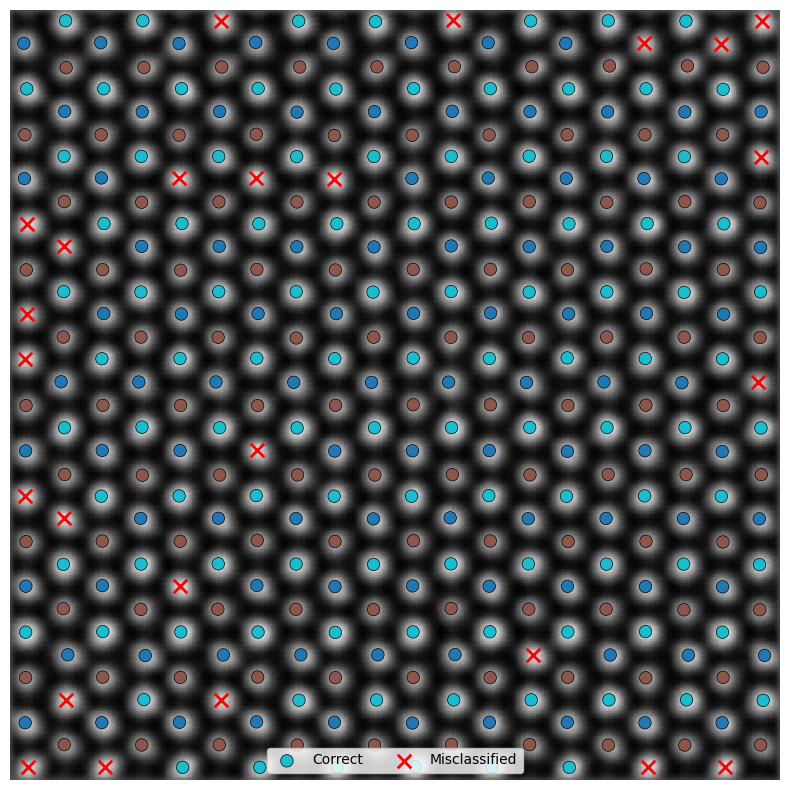

DOSE: 10000.0


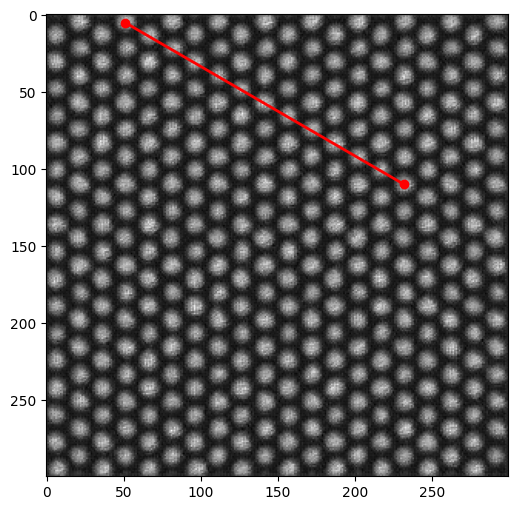

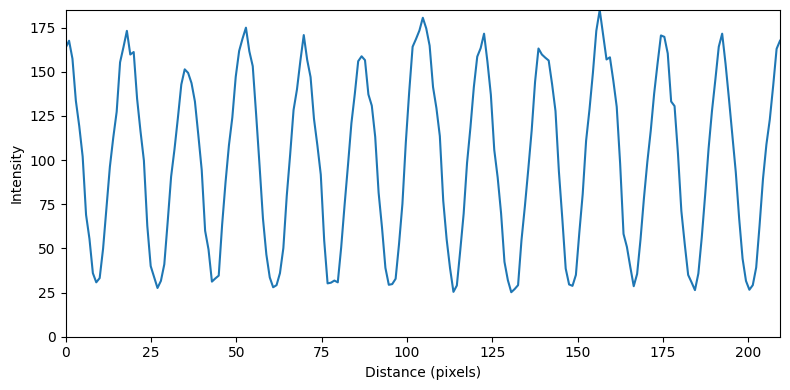

Detected 340 Gaussian peaks.


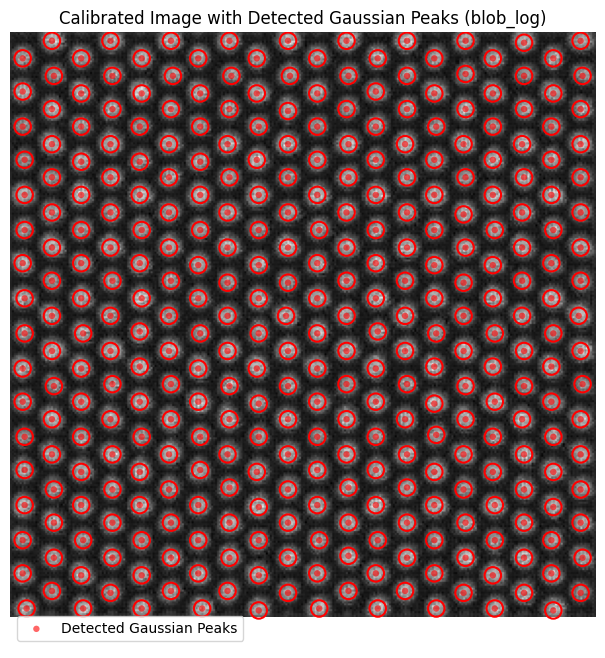

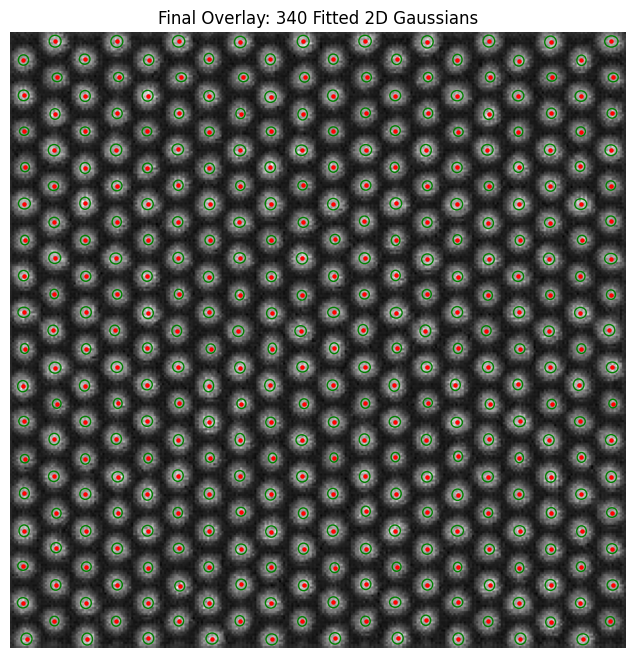

Successfully fitted and plotted 340 Gaussians.
===== METRICS =====
Total Gaussians: 340
Matched: 340
Accuracy: 0.6529

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [134.05896385 148.44593993 118.11458357]
Cluster mapping: {2: np.int32(1), 0: np.int32(0), 1: np.int32(2)}

Confusion Matrix:
[[71 12 28]
 [33 75  3]
 [41  1 76]]

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.64      0.55       111
           1       0.85      0.68      0.75       111
           2       0.71      0.64      0.68       118

    accuracy                           0.65       340
   macro avg       0.68      0.65      0.66       340
weighted avg       0.68      0.65      0.66       340

Misclassified points: 118


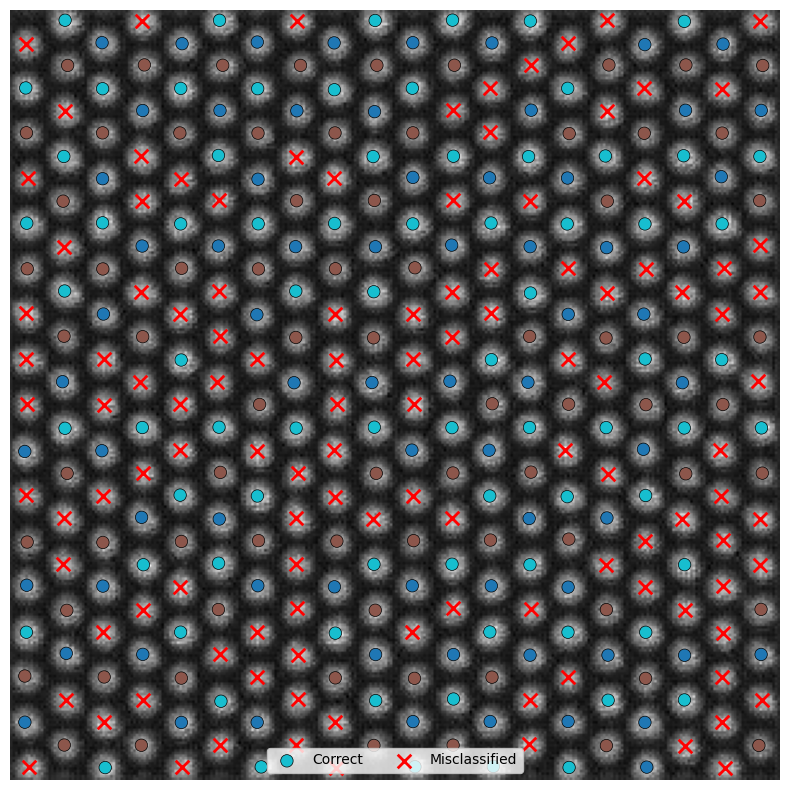

DOSE: 5000.0


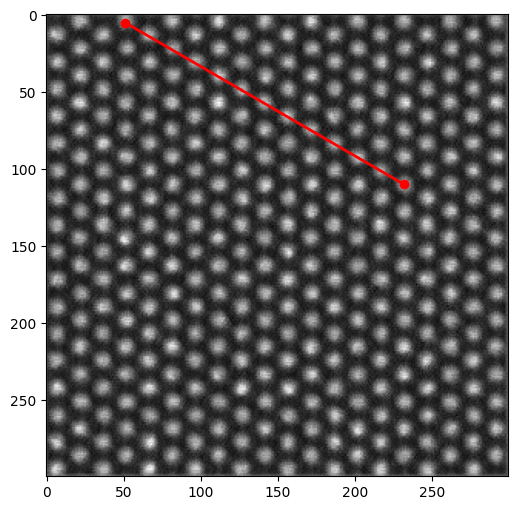

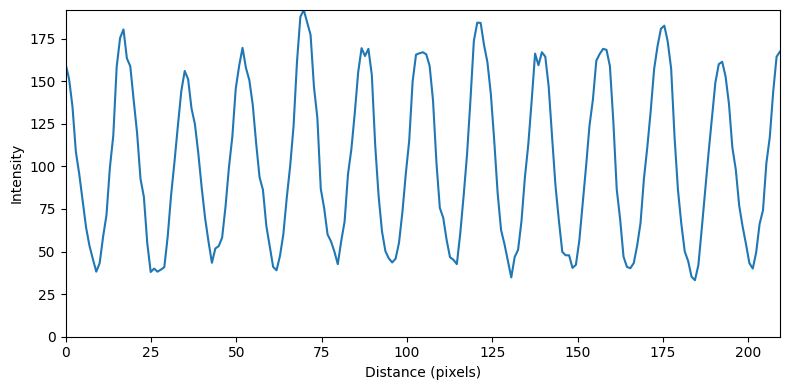

Detected 340 Gaussian peaks.


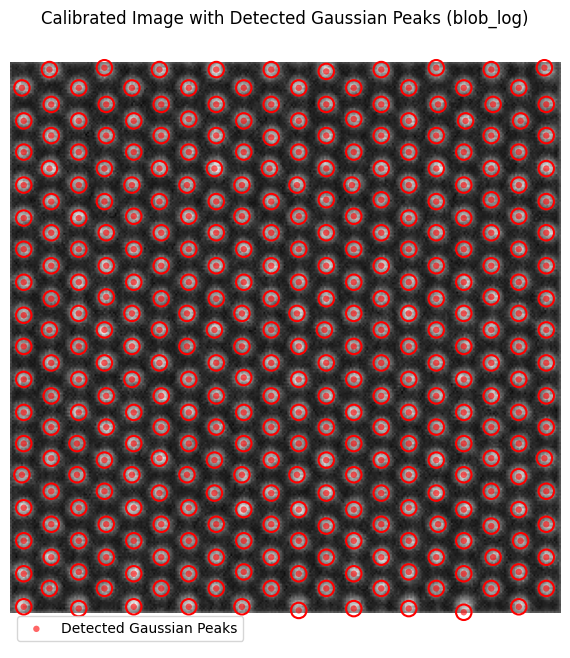

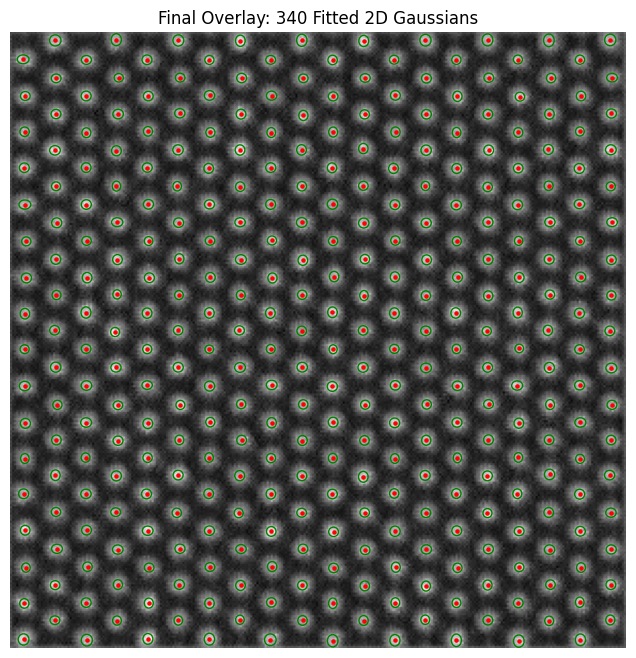

Successfully fitted and plotted 340 Gaussians.
===== METRICS =====
Total Gaussians: 340
Matched: 340
Accuracy: 0.5000

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [127.0082536  172.0155302  147.46673175]
Cluster mapping: {0: np.int32(1), 2: np.int32(0), 1: np.int32(2)}

Confusion Matrix:
[[56 48  7]
 [22 84  5]
 [49 39 30]]

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.50      0.47       111
           1       0.49      0.76      0.60       111
           2       0.71      0.25      0.38       118

    accuracy                           0.50       340
   macro avg       0.55      0.51      0.48       340
weighted avg       0.55      0.50      0.48       340

Misclassified points: 170


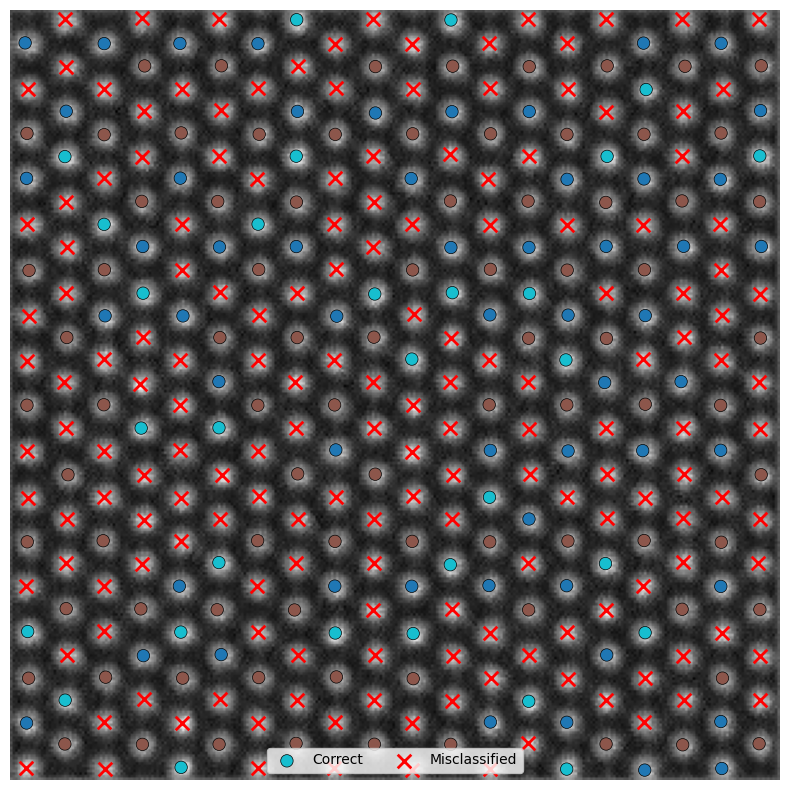

DOSE: 1000.0


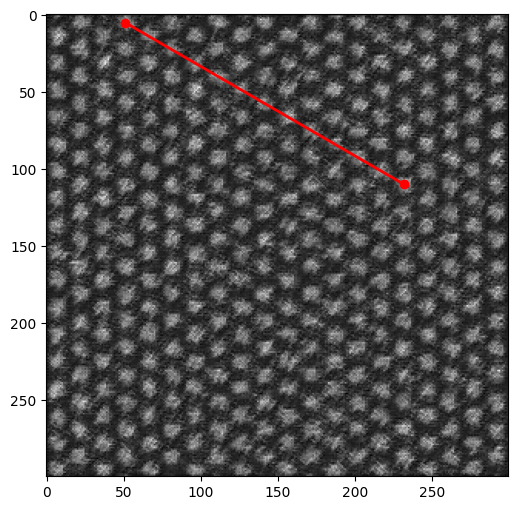

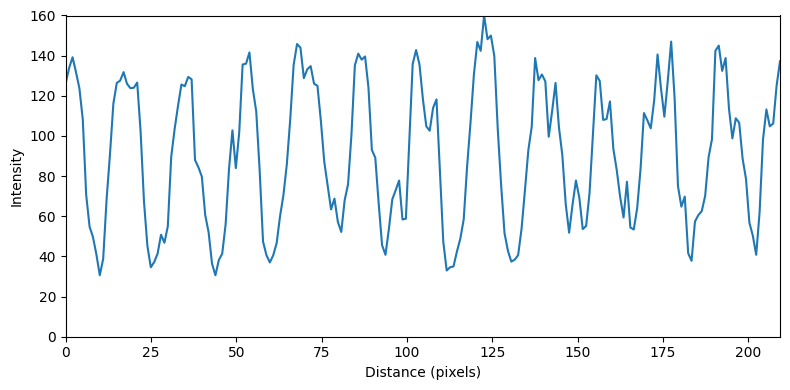

Detected 119 Gaussian peaks.


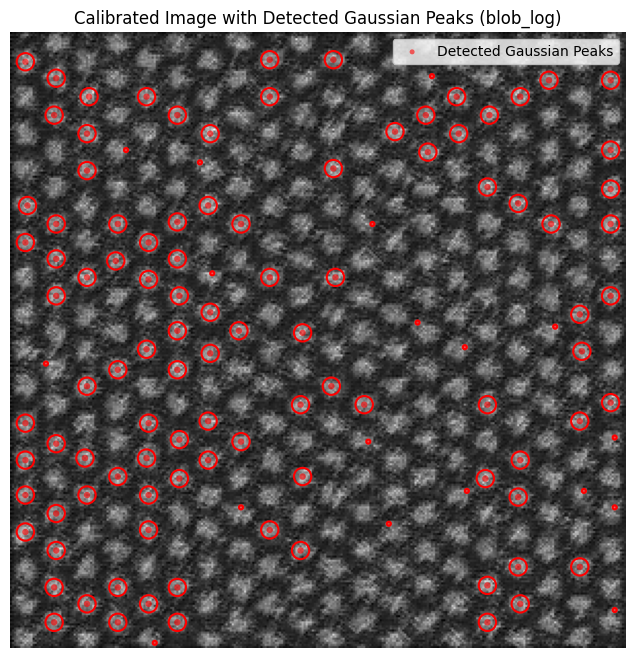

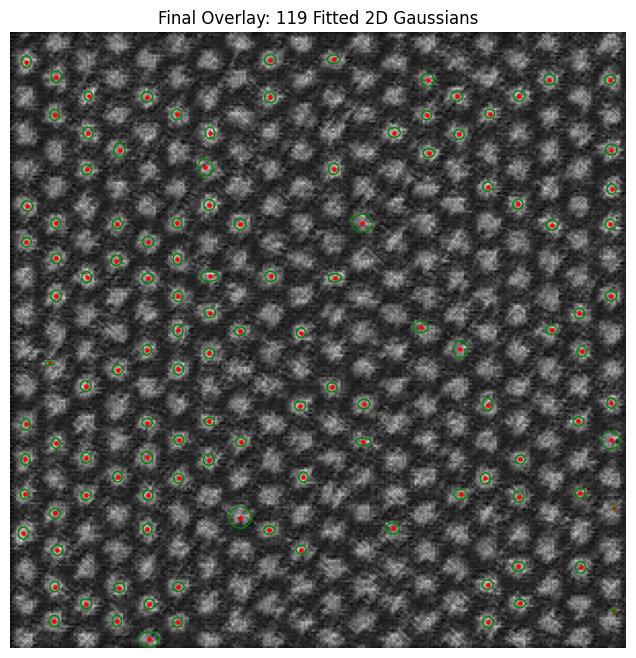

Successfully fitted and plotted 119 Gaussians.
===== METRICS =====
Total Gaussians: 119
Matched: 119
Accuracy: 0.3445

Reference class means: {np.int32(0): np.float64(160.274511387476), np.int32(1): np.float64(123.09720683493472), np.int32(2): np.float64(199.21771387647829)}
Denoised cluster centers: [125.47279397 254.79581039 102.35944664]
Cluster mapping: {2: np.int32(1), 0: np.int32(0), 1: np.int32(2)}

Confusion Matrix:
[[12 32  0]
 [ 9 29  1]
 [12 24  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.27      0.31        44
           1       0.34      0.74      0.47        39
           2       0.00      0.00      0.00        36

    accuracy                           0.34       119
   macro avg       0.23      0.34      0.26       119
weighted avg       0.25      0.34      0.27       119

Misclassified points: 78


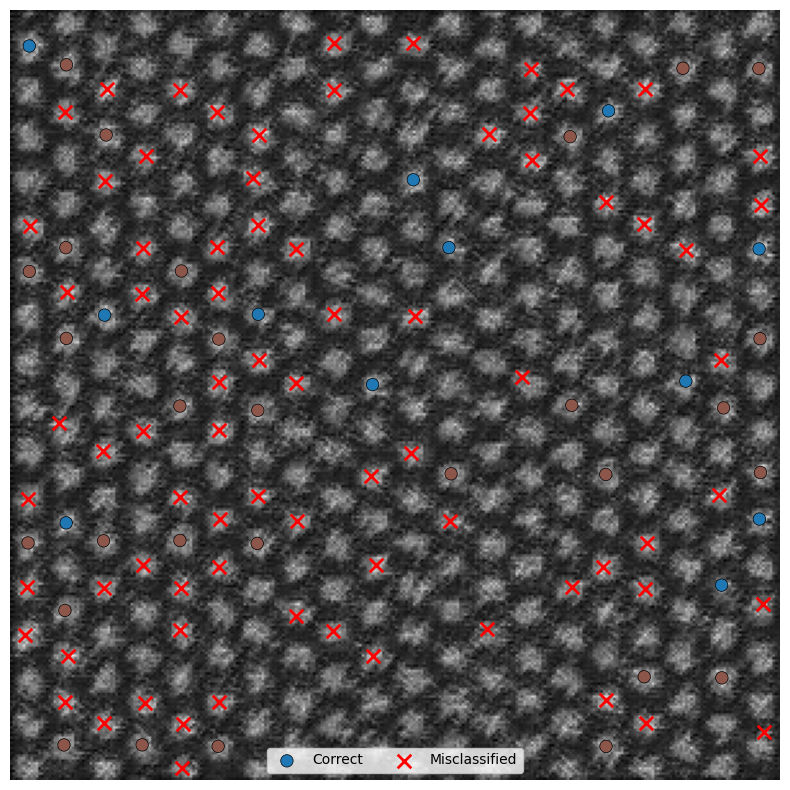

In [ ]:
imgs_hybrid = []
results_hybrid   = []
for dose in doses:
  print(f'DOSE: {dose}')
  path_to_images = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_MXENE/denoised_hybrid/'
  path_to_image = path_to_images + f'080kVTi3C2O2-DEMO-080kV-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif'
  image = convert(tifffile.imread(path_to_image))

  start = (5, 51)   # (row, column)
  end   = (110, 232)

  distance, intensity = get_linescan(
      image,
      start,
      end,
      linewidth=5)
  imgs_hybrid .append(image)
  result, y_true, y_pred, matched_pos, mis_pos = classify_intensities(image, X_clean, y_clean, verbose=True)
  results_hybrid .append([result, y_true, y_pred, matched_pos, mis_pos])

# Noisy

In [ ]:
imgs_noisy = []
results_noisy   = []
for dose in doses:
  path_to_images = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_MXENE/'
  path_to_image = path_to_images + f'080kVTi3C2O2-DEMO-080kV-jittered_interp_0.1_dose_{dose}.tif'
  image = convert(tifffile.imread(path_to_image))
  imgs_noisy .append(image)
  result, y_true, y_pred, matched_pos, mis_pos = classify_intensities(image, model, X_clean, y_clean, verbose=True)
  results_noisy .append([result, y_true, y_pred, matched_pos, mis_pos])

# Plotting

In [ ]:
def plot_classification(ax, y_true, y_pred, matched_pos, mis_pos, point_size = 80):
  mis_mask = (y_true != y_pred)
  ax.scatter(
        matched_pos[~mis_mask, 0],
        matched_pos[~mis_mask, 1],
        c=y_pred[~mis_mask],
        cmap="tab10",
        s=point_size,
        edgecolors="k",
        linewidths=0.5,
        label="Correct"
    )


  ax.scatter(
      mis_pos[:, 0],
      mis_pos[:, 1],
      marker="x",
      c="red",
      s=point_size * 1.2,
      linewidths=2,
      label="Misclassified"
  )

In [ ]:
k = 3
images = [imgs_noisy[k], imgs_hybrid[k], imgs_lobato[k], imgs_pinto[k], imgs_unit[k]]
y_true = [results_noisy[k][1], results_hybrid[k][1], results_lobato[k][1], results_pinto[k][1],results_unit[k][1]]
y_pred = [results_noisy[k][2], results_hybrid[k][2], results_lobato[k][2], results_pinto[k][2],results_unit[k][2]]
matched_pos = [results_noisy[k][3], results_hybrid[k][3], results_lobato[k][3], results_pinto[k][3],results_unit[k][3]]
mis_pos = [results_noisy[k][4], results_hybrid[k][4], results_lobato[k][4], results_pinto[k][4],results_unit[k][4]]

In [ ]:
n = len(images)
sub = 2
models = ["Noisy", "Hybrid", "Lobato", "Pinto", "UNIT"]
letters_img = ["(a)", "(b)", "(c)", "(d)", "(e)"]
letters_imgs_c = ["(f)", "(g)", "(h)", "(i)", "(j)"]

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images):
  ax_img = fig.add_subplot(gs[0, idx])
  ax_img.imshow(image, cmap='gray')
  ax_img.axis('off')

  ax_img.text(0.015, 0.95, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  ax_img.text(0.95, 0.95, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  ax_img = fig.add_subplot(gs[1, idx])
  ax_img.imshow(image, cmap='gray')
  plot_classification(ax_img, y_true[idx], y_pred[idx], matched_pos[idx], mis_pos[idx], point_size = 70)
  ax_img.axis('off')

  ax_img.text(0.95, 0.95, letters_imgs_c[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))




